# BTD: separate a multichannel image

A multichannel image (for example a multispectral image) records several numbers per pixel,
one per channel. When the scene is made of a few components, each with its own spatial
layout and its own spectrum, the image is a sum of terms *spatial map × spectrum*. This is
the **BTD** model with rank-(L, L, 1) terms (see [BTD](../models/btd.md)).

This tutorial draws such an image from random factors, then recovers its terms with
{class}`~pybbtd.btd.BTD` and the ALS solver.

## The data

80 × 100 pixels and 4 channels. There are R = 3 terms whose spatial maps have rank L = 5.
The true factors are random, and we add 1% noise.

In [1]:
import numpy as np

from pybbtd import BTD
from pybbtd.btd import factors_to_tensor
from pybbtd.visualization import plot_error

np.random.seed(0)
R, L = 3, 5
model = BTD((80, 100, 4), R, L)

A0 = np.random.randn(80, R * L)  # spatial map of term r: A0_r @ B0_r.T
B0 = np.random.randn(100, R * L)
C0 = np.random.randn(4, R)  # one 4-value signature per term
T0 = factors_to_tensor(A0, B0, C0, model.get_constraint_matrix())
T = T0 + 0.01 * np.linalg.norm(T0) / np.sqrt(T0.size) * np.random.randn(*T0.shape)
T.shape

(80, 100, 4)

## Fit the model

First check that these sizes and ranks guarantee a unique answer
(see [Ranks and uniqueness](../guides/ranks-and-uniqueness.md)):

In [2]:
model.check_uniqueness()

True

Fit with two different starting points: random factors, and factors taken from the
singular value decomposition (SVD) of the data.

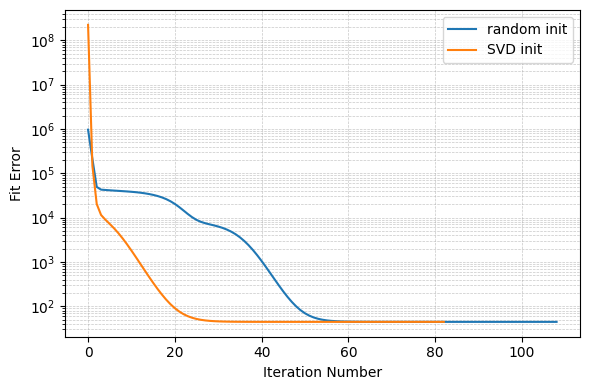

In [3]:
model.fit(T, init="random", max_iter=3000, rel_tol=1e-10, abs_tol=0)
random_init_error = model.fit_error

model.fit(T, init="svd", max_iter=3000, rel_tol=1e-10, abs_tol=0)
svd_init_error = model.fit_error

plot_error([random_init_error, svd_init_error], labels=["random init", "SVD init"])

Both runs reach the same error. ALS can also stop at a poorer solution from some starting
points; comparing the final errors of a few runs reveals it
(see [Initialization and convergence](../guides/fitting.md)).

## Check the result

The estimated factors are in `model.factors`, and the tensor they rebuild in
`model.tensor`. It is closer to the clean tensor `T0` than the noisy data are, which were
1% away from it:

In [4]:
A, B, C = model.factors
np.linalg.norm(model.tensor - T0) / np.linalg.norm(T0)

np.float64(0.002870193511648867)